In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss_and_mae, evaluate_model 

from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense
from sklearn.preprocessing import StandardScaler

from pandas import DataFrame
from pandas import concat

I0000 00:00:1793982208.553249 1962689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793982208.583874 1962689 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793982209.319654 1962689 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,1.2796,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,266.0,6.0,146.0,126.0,426.0,406.0,0.0,0.0,0.000000,0.000000
1,1,1.0,2.7716,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,266.0,6.0,146.0,126.0,426.0,406.0,0.0,0.0,0.000000,0.000000
2,2,0.0,23.1230,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,98.0,6.0,-42.0,-42.0,238.0,238.0,-188.0,-168.0,1.709091,1.527273
3,3,1.0,25.1985,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,100.0,6.0,-30.0,-40.0,250.0,240.0,-176.0,-166.0,1.600000,1.509091
4,4,2.0,27.3368,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,104.0,6.0,-10.0,-36.0,270.0,244.0,-156.0,-162.0,1.418182,1.472727


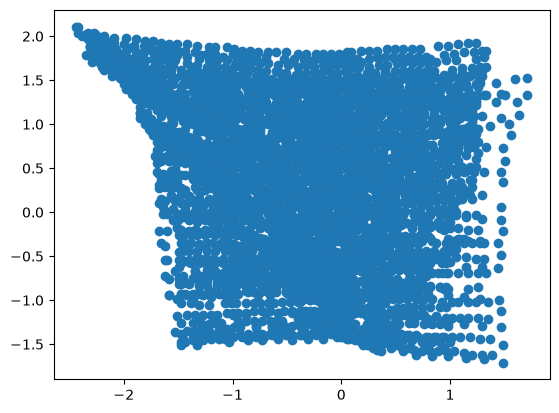

In [2]:
data_concat = pd.read_csv("processed_data/29Oct_data.csv")
display(data_concat.head())
data_concat.dtypes
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - Remove NaNs and convert to float32

In [3]:
data_concat = data_concat.astype("float32")
data_concat = data_concat.dropna()

<h3>MLP Inverse - with displacement?

In [29]:
data_concat["cx_diff"] = data_concat["cx_mm"].diff()
data_concat["cy_diff"] = data_concat["cy_mm"].diff()

dataset_test = data_concat.tail(442).reset_index()
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].drop(data_concat.tail(442).index) #reset indexes as multiple datapoints combined #,"cx_diff","cy_diff"

dataset

,cx_mm,cy_mm,s0,s1,s2
0,0.000000,0.000000,0.0,0.0,0.0
1,0.000000,0.000000,0.0,0.0,0.0
2,1.709091,1.527273,6144.0,-8393.0,2249.0
3,1.600000,1.509091,6144.0,-7949.0,1805.0
4,1.418182,1.472727,6144.0,-7506.0,1362.0
...,...,...,...,...,...
3667,0.400000,-0.963636,-4608.0,-1243.0,5851.0
3668,0.563636,-0.963636,-4608.0,-1687.0,6295.0
3669,0.727273,-0.981818,-4608.0,-2130.0,6738.0
3670,0.745455,-1.163636,-5120.0,-1874.0,6994.0


don't window output motor values

In [37]:
X_train = dataset[["cx_mm", "cy_mm"]].drop(0) #, "cx_diff", "cy_diff"
y_train_all = dataset[["s0", "s1", "s2"]].drop(0)

X_test = dataset_test[["cx_mm", "cy_mm"]].drop(0) #, "cx_diff", "cy_diff"
y_test_all = dataset_test[["s0", "s1", "s2"]].drop(0)


# print(y_train_all)
y_train = y_train_all[["s0", "s1"]] #calculate s2 from s2 = -(s0 + s1) to ensure they all sum to 0
y_test = y_test_all[["s0", "s1"]]

scalerX = StandardScaler().fit(X_train)
scalerY = StandardScaler().fit(y_train)


X_train_scaled = scalerX.transform(X_train)
y_train_scaled = scalerY.transform(y_train)

X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

In [70]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(dataset.values)
scaled_test_data = scaler.fit_transform(dataset_test.values)

def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        # print(data[i, 3])
        X.append(data[i:(i + time_step), 0:3])
        y.append(data[i + time_step, 3:5])
    return np.array(X), np.array(y)


time_step = 100
X, y = create_dataset(scaled_data, time_step)
X_test, y_test = create_dataset(scaled_test_data, time_step)
# X = X.reshape(X.shape[0], X.shape[1], 1)
display(y)
display(X)

array([[-1.933351  ,  0.7852485 ],
       [-1.8079995 ,  0.66032505],
       [-1.682648  ,  0.5354016 ],
       ...,
       [-0.45120314,  1.7626407 ],
       [-0.5765547 ,  1.8875642 ],
       [-0.5041168 ,  1.9597547 ]], shape=(3325, 2), dtype=float32)

array([[[ 0.33495522, -0.28476414, -0.01349397],
        [ 0.33495522, -0.28476414, -0.01349397],
        [ 2.3029249 ,  1.295676  ,  1.7120551 ],
        ...,
        [ 1.9679513 ,  1.0134546 ,  1.2806678 ],
        [ 2.1982455 ,  1.0134546 ,  1.2806678 ],
        [ 2.2191815 ,  0.86293644,  1.1368722 ]],

       [[ 0.33495522, -0.28476414, -0.01349397],
        [ 2.3029249 ,  1.295676  ,  1.7120551 ],
        [ 2.1773098 ,  1.2768612 ,  1.7120551 ],
        ...,
        [ 2.1982455 ,  1.0134546 ,  1.2806678 ],
        [ 2.2191815 ,  0.86293644,  1.1368722 ],
        [ 2.0307589 ,  0.82530695,  1.1368722 ]],

       [[ 2.3029249 ,  1.295676  ,  1.7120551 ],
        [ 2.1773098 ,  1.2768612 ,  1.7120551 ],
        [ 1.9679513 ,  1.2392317 ,  1.7120551 ],
        ...,
        [ 2.2191815 ,  0.86293644,  1.1368722 ],
        [ 2.0307589 ,  0.82530695,  1.1368722 ],
        [ 1.8214003 ,  0.8441217 ,  1.1368722 ]],

       ...,

       [[-0.858388  , -0.2095051 , -0.588677  ],
        [-1

In [73]:
model = Sequential([
    GRU(64, activation='tanh', return_sequences=True, input_shape=(X.shape[1], 3)),  
    GRU(32, activation='tanh'),  
    Dense(2, activation='sigmoid')  
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', 'mae'])
model.summary()

history = model.fit(X, y, epochs=10, batch_size=16)

/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_39 (GRU)                    │ (None, 100, 64)        │        13,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_40 (GRU)                    │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,722 (88.76 KB)

 Trainable params: 22,722 (88.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


208/208 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8782 - loss: -2.8681 - mae: 0.6447
Epoch 2/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9525 - loss: -6.1778 - mae: 0.6063
Epoch 3/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9570 - loss: -8.8254 - mae: 0.6129
Epoch 4/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9612 - loss: -11.4890 - mae: 0.6144
Epoch 5/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9636 - loss: -14.1161 - mae: 0.6155
Epoch 6/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9621 - loss: -16.6924 - mae: 0.6184
Epoch 7/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9672 - loss: -19.2712 - mae: 0.6205
Epoch 8/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9714 - loss: -21.8762 - mae: 0.6217
Epoch 9/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9708 - loss: -24.4345 - mae: 0.6232
Epoch 10/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9747 - loss: -26.89

In [74]:
y_pred = model.predict(X_test, verbose=0)
evaluate_model("Displacement MLP", y_test, y_pred, is_scaled=True)


Displacement MLP Results (scaled):
  Overall R2:  -0.6611
  Weighted R2: -0.5851


(-0.6610733445135506, -0.5850651599402953)

-26.89727020263672


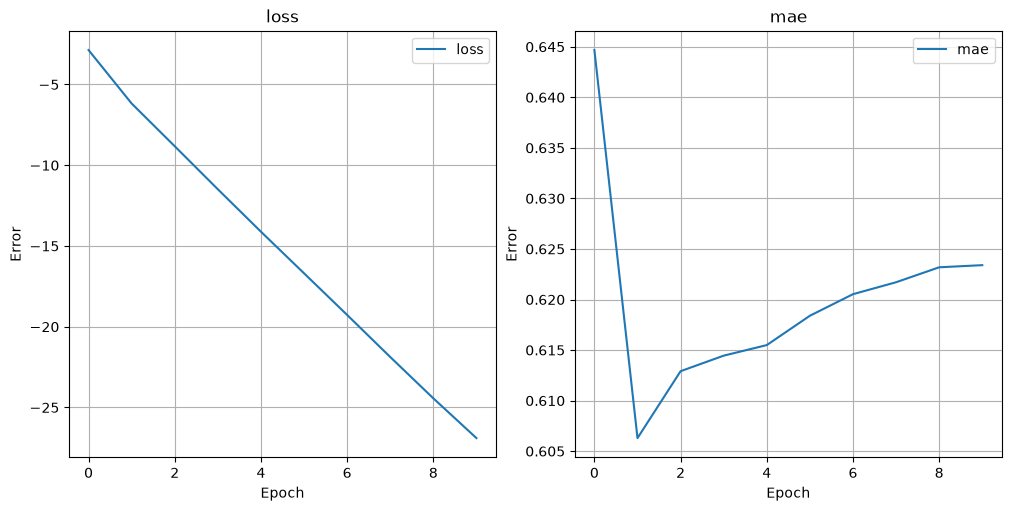

In [75]:
def plot_loss_and_mae(history):
  fig, axs = plt.subplots(1, 2, figsize=(10,5), constrained_layout=True)
  for i, value in enumerate(['loss', 'mae']):
    subplot = axs[i]
    subplot.plot(history.history[value], label=value)
    # subplot.plot(history.history[f'val_{value}'], label=f'val_{value}')
  #   plt.ylim([0, 10])
    subplot.set_xlabel('Epoch')
    subplot.set_ylabel('Error')
    subplot.legend()
    subplot.grid(True)
    subplot.set_title(value)
plot_loss_and_mae(history)
print(history.history['loss'][-1])

In [ ]:
test_results_dnn_standard = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
test_results_dnn_standard

high r2 score.

Predictions are also pretty good, with only a couple that are slightly off.
Possibly overfitting to this data. 

In [ ]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test_scaled)
y_pred_inverse = DataFrame(y_pred_inverse)
y_pred_inverse_all = y_pred_inverse
y_pred_inverse_all[2]= -(y_pred_inverse_all[0] + y_pred_inverse_all[1])
y_pred_inverse


In [ ]:
y_pred_inverse

In [ ]:
fig, axs = plt.subplots(1,4, figsize=(15,5), constrained_layout=True)
subplot = axs[0]
subplot.scatter(y_test_inverse, y_pred_inverse)
subplot.set_xlabel('True Values')
subplot.set_ylabel('Predictions')
lims = [-11000, 10000]
# plt.xlim(lims)
# plt.ylim(lims)
_ = subplot.plot(lims, lims, color="red")
subplot.title("All")
print(len(y_test_scaled), len(y_pred))

for i, label in enumerate(['s0', 's1', 's2']):
    subplot = axs[i]
    subplot.scatter(y_test_all[label], y_pred_inverse_all[i])
    lims = [-10000, 10000]
    subplot.set_xlabel('True Values')
    subplot.set_ylabel('Predictions')
    # subplot.set_xlim(lims)
    # subplot.set_ylim(lims)
    _ =subplot.plot(lims, lims, color="red")
    subplot.set_title(label)
fig.suptitle("16th Oct Windowed Test Predictions not flattened")

<h2> Predicting for normal square - snake



In [ ]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [ ]:
X_scaled_0020 = scalerX.transform(cxcy_window_0020)

In [ ]:
snake_predictions = model.predict(X_scaled_0020)

In [ ]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [ ]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_Window_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')